### Data Science Final Project

## Pengelompokan Pola Gerak dan Aktivitas Manusia Berdasarkan Sinyal Smartphone Menggunakan Agglomerative Hierarchical Clustering


### BUSINESS UNDERSTANDING
#### Masalah
Pengenalan aktivitas manusia (Human Activity Recognition / HAR) berbasis sensor smartphone telah menjadi komponen krusial dalam pengembangan teknologi kesehatan digital. Dataset yang digunakan dalam eksperimen ini sejatinya telah memiliki enam label aktivitas asli, yaitu WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, dan LAYING. Namun, dalam implementasi di skenario dunia nyata, proses anotasi data sensor berskala besar sangat mahal, membutuhkan keterlibatan pakar, dan memakan waktu yang lama. Oleh karena itu, proyek ini difokuskan pada pendekatan unsupervised learning (Clustering). 

#### Pertanyaan
Tujuan utama proyek ini adalah menerapkan Agglomerative Hierarchical Clustering untuk mengelompokkan pola aktivitas manusia berdasarkan 561 fitur numerik sensor smartphone, serta membandingkan konfigurasi linkage Ward, Complete, dan Average untuk memperoleh gambaran kualitas pengelompokan. Kemudian ada beberapa pertanyaan pendukung yang harapannya bisa terjawab seiring berjalannya proyek ini. Pertanyaan-pertanyaan tersebut tertera sebagai berikut:
1) Bagaimana Agglomerative Hierarchical Clustering membentuk kelompok aktivitas berdasarkan fitur sensor smartphone?
2) Bagaimana perbedaan linkage Ward, Complete, dan Average mempengaruhi kualitas hasil clustering?
3) Seberapa baik kualitas klaster berdasarkan matrik evaluasi internal?
4) Seberapa sesuai hasil pengelompokan dengan enam label aktivitas asli berdasarkan matrik evaluasi eksternal?

#### Metode 
Penelitian ini menggunakan algoritma Agglomerative Hierarchical Clustering, yaitu metode unsupervised learning yang mengelompokkan data berdasarkan kemiripan karakteristiknya.
Proses clustering dimulai dengan menganggap setiap sampel sebagai satu kluster tersendiri. Selanjutnya, kluster yang memiliki kedekatan berdasarkan kriteria tertentu digabungkan secara bertahap hingga terbentuk struktur hierarki.
Dalam penelitian ini, pengelompokan dilakukan berdasarkan 561 fitur numerik yang berasal dari sensor accelerometer dan gyroscope pada smartphone. Label aktivitas asli tidak digunakan dalam pembentukan kluster, tetapi dimanfaatkan untuk mengevaluasi kesesuaian hasil pengelompokan.

#### Metrik
A. Metrik Evaluasi Internal
1. Silhouette Coefficient
Silhouette Coefficient digunakan untuk mengukur seberapa dekat suatu sampel dengan klusternya dibandingkan dengan kluster lain. Nilainya berada pada rentang -1 hingga 1. Nilai yang lebih tinggi secara umum menunjukkan bahwa sampel lebih sesuai dengan kluster tempatnya berada.
2. Davies-Bouldin Index
Davies-Bouldin Index mengukur kualitas kluster berdasarkan kedekatan antaranggota dalam kluster dan perbedaan antar-kluster. Nilai yang lebih rendah menunjukkan hasil pengelompokan yang lebih baik berdasarkan metrik ini.
3. Calinski-Harabasz Index
Calinski-Harabasz Index membandingkan variasi antar-kluster dengan variasi di dalam kluster. Nilai yang lebih tinggi secara umum menunjukkan pemisahan kelompok yang lebih baik.

B. Metrik Evaluasi Eksternal
1. Adjusted Rand Index (ARI)
ARI digunakan untuk mengukur kesesuaian antara hasil pengelompokan dengan label aktivitas asli, dengan memperhitungkan kesesuaian yang mungkin terjadi secara acak. Nilai yang mendekati 1 menunjukkan kesesuaian yang tinggi, sedangkan nilai sekitar 0 menunjukkan kesesuaian yang sebanding dengan pengelompokan acak.
2. Normalized Mutual Information (NMI)
NMI digunakan untuk mengukur hubungan informasi antara hasil kluster dan label aktivitas asli. Nilai yang lebih tinggi menunjukkan hubungan yang lebih kuat antara kedua pengelompokan tersebut.
Keberhasilan proyek tidak hanya ditentukan oleh satu metrik. Hasil dari seluruh metrik akan dianalisis secara bersama-sama dengan mempertimbangkan jumlah kluster, konfigurasi linkage, dan interpretasi karakteristik aktivitas. Label aktivitas asli digunakan untuk evaluasi eksternal, bukan sebagai dasar pembentukan kluster.



### DATA GATHERING

##### Sumber dan Tautan Dataset
- Nama Dataset: Human Activity Recognition (HAR) Using Smartphones.   
- Sumber Repositori: UCI Machine Learning Repository (ID: 240).   
- Tautan Resmi: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones.   
- Lisensi: Creative Commons Attribution 4.0 International (CC BY 4.0).   
##### Pengertian dan Struktur Dataset
Dataset ini berisi rekaman aktivitas fisik harian yang dilakukan oleh 30 relawan (berusia 19–48 tahun) yang mengenakan smartphone Samsung Galaxy S II di bagian pinggang. Menggunakan sensor inersia internal (accelerometer dan gyroscope), tercatat sinyal percepatan linier 3-aksial (total acceleration dan body acceleration) serta kecepatan sudut 3-aksial (angular velocity) pada frekuensi sampling 50 Hz.   Sinyal mentah diproses awal menggunakan pemotongan sliding window berdurasi 2,56 detik (128 pembacaan sinyal) dengan overlap 50%. Dari setiap jendela geser, diekstrak 561 fitur numerik dalam domain waktu (awalan t) dan domain frekuensi (awalan f hasil transformasi FFT).   

##### Arti Kelompok Kolom/Fitur Utama:
`Subject`: Identitas anonim relawan (angka 1 s.d. 30).   
`Activity`: Label aktivitas aktual (Ground Truth) yang terdiri dari 6 kelas: WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS, SITTING, STANDING, dan LAYING.   
`Fitur Sinyal Domain Waktu` (tBodyAcc-XYZ, tGravityAcc-XYZ, tGyro-XYZ): Mengukur percepatan gerakan tubuh, komponen gaya gravitasi, dan kecepatan sudut putaran tubuh pada 3 sumbu ($X, Y, Z$).   
`Fitur Turunan` (tBodyAccJerk-XYZ, tBodyAccMag, dll.): Mengukur sentakan gerakan mendadak (Jerk) dan besaran vektor total (Magnitude) menggunakan Euclidean norm.   
`Fitur Domain Frekuensi` (fBodyAcc-XYZ, fGyro-XYZ): Hasil transformasi fourier (FFT) untuk menganalisis frekuensi gerak. 

##### Alasan Memilih Dataset Ini:
Representatif & Kompleks: Memiliki 561 fitur numerik yang sudah dinormalisasi pada $[-1, 1]$, ideal untuk pengujian reduksi dimensi dan algoritma Agglomerative Hierarchical Clustering.   Relevansi Use-Case: Mendukung otomasi klasifikasi pola hidup sehat (gerak aktif vs. sedenter) pada wearable devices tanpa bergantung pada input manual 

In [1]:
# Import Library
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
# 1. Definisi Path Lokal
base_path = 'UCI HAR Dataset/'

# 2. Buka daftar fitur (features.txt) & tangani duplicate names
features = pd.read_csv(base_path + 'features.txt', sep=r'\s+', header=None, names=['idx', 'name'])

# Fungsi untuk membuat nama kolom unik jika ada duplikat nama pada features.txt
def make_unique(names):
    seen = {}
    unique_names = []
    for name in names:
        if name in seen:
            seen[name] += 1
            unique_names.append(f"{name}_{seen[name]}")
        else:
            seen[name] = 0
            unique_names.append(name)
    return unique_names

column_names = make_unique(features['name'].values)

# 3. Buka Peta Label Aktivitas
activity_labels = pd.read_csv(base_path + 'activity_labels.txt', sep=r'\s+', header=None, names=['id', 'activity_name'])

# 4. Muat Data Train dan Test
X_train = pd.read_csv(base_path + 'train/X_train.txt', sep=r'\s+', header=None, names=column_names)
y_train = pd.read_csv(base_path + 'train/y_train.txt', sep=r'\s+', header=None, names=['Activity_ID'])
sub_train = pd.read_csv(base_path + 'train/subject_train.txt', sep=r'\s+', header=None, names=['Subject'])

X_test = pd.read_csv(base_path + 'test/X_test.txt', sep=r'\s+', header=None, names=column_names)
y_test = pd.read_csv(base_path + 'test/y_test.txt', sep=r'\s+', header=None, names=['Activity_ID'])
sub_test = pd.read_csv(base_path + 'test/subject_test.txt', sep=r'\s+', header=None, names=['Subject'])

# 5. Penggabungan Data Train + Test (Unsupervised Learning butuh dataset utuh)
X_raw = pd.concat([X_train, X_test], ignore_index=True)
y_raw = pd.concat([y_train, y_test], ignore_index=True)
sub_raw = pd.concat([sub_train, sub_test], ignore_index=True)

# Gabungkan ke dalam satu DataFrame mentah (df_raw)
df_raw = X_raw.copy()
df_raw['Subject'] = sub_raw['Subject']
df_raw['Activity_ID'] = y_raw['Activity_ID']
df_raw['Activity'] = df_raw['Activity_ID'].map(dict(zip(activity_labels['id'], activity_labels['activity_name'])))

print("=== GATHERING COMPLETED ===")
print(f"Bentuk Dataset Mentah: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")

=== GATHERING COMPLETED ===
Bentuk Dataset Mentah: 10299 baris, 564 kolom


### EDA
Pada tahap ini, kita mengekplorasi statistik deskriptif dan visualisasi data untuk memahami sebaran aktivitas, keseimbangan sampel relawan, serta perbedaan karakteristik energi sinyal antara aktivitas gerak dinamis dan statis

=== STATISTIK DESKRIPTIF BEBERAPA FITUR UTAMA ===
                        mean       std  min       50%  max
tBodyAcc-mean()-X   0.274347  0.067628 -1.0  0.277174  1.0
tBodyGyro-mean()-X -0.030982  0.183186 -1.0 -0.027763  1.0
tBodyAccMag-mean() -0.548222  0.467094 -1.0 -0.874635  1.0


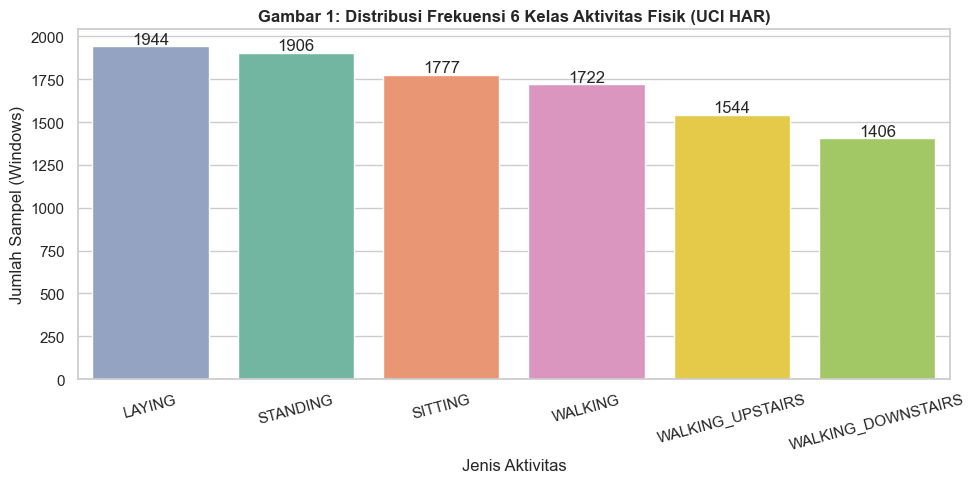

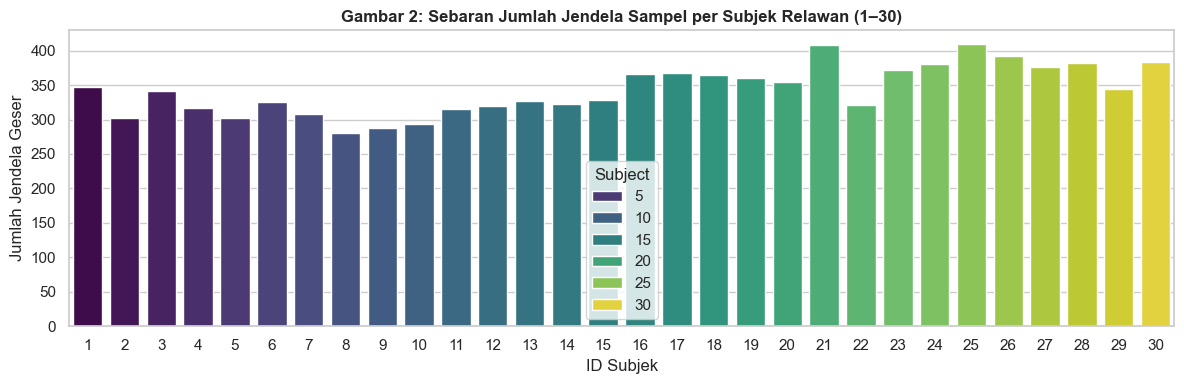

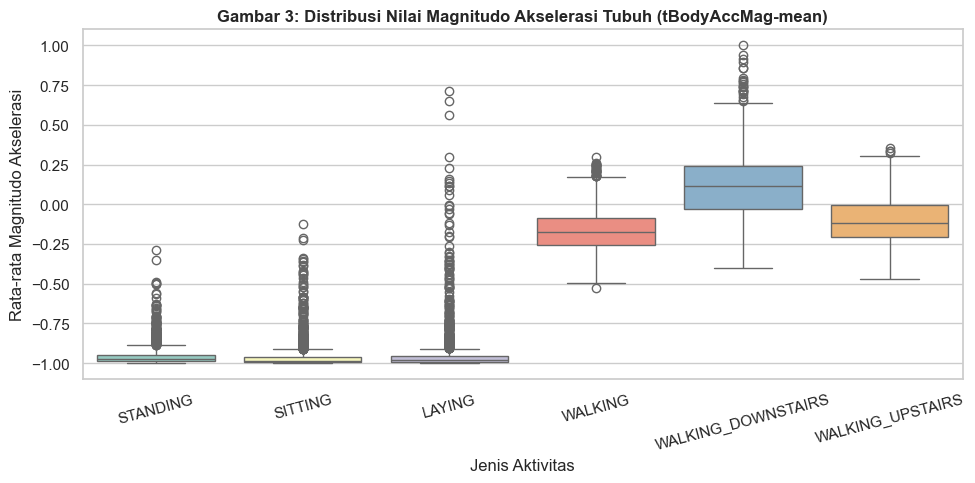

In [3]:
# 3. EXPLORATORY DATA ANALYSIS (EDA)

# A. STATISTIK DESKRIPTIF AKSI FITUR UTAMA
print("=== STATISTIK DESKRIPTIF BEBERAPA FITUR UTAMA ===")
sample_cols = ['tBodyAcc-mean()-X', 'tBodyGyro-mean()-X', 'tBodyAccMag-mean()']
print(df_raw[sample_cols].describe().T[['mean', 'std', 'min', '50%', 'max']])

# B. VISUALISASI 1: Distribusi Proporsi Kelas Aktivitas
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df_raw, x='Activity', hue='Activity',palette='Set2', order=df_raw['Activity'].value_counts().index)
plt.title("Gambar 1: Distribusi Frekuensi 6 Kelas Aktivitas Fisik (UCI HAR)", fontsize=12, fontweight='bold')
plt.xlabel("Jenis Aktivitas")
plt.ylabel("Jumlah Sampel (Windows)")
plt.xticks(rotation=15)

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.show()

# C. VISUALISASI 2: Kontribusi Sampel per Subjek
plt.figure(figsize=(12, 4))
sns.countplot(data=df_raw, x='Subject', hue='Subject', palette='viridis')
plt.title("Gambar 2: Sebaran Jumlah Jendela Sampel per Subjek Relawan (1–30)", fontsize=12, fontweight='bold')
plt.xlabel("ID Subjek")
plt.ylabel("Jumlah Jendela Geser")
plt.tight_layout()
plt.show()

# D. VISUALISASI 3: Perbandingan Energetik (Dinamis vs Statis)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_raw, x='Activity', y='tBodyAccMag-mean()', hue='Activity', palette='Set3')
plt.title("Gambar 3: Distribusi Nilai Magnitudo Akselerasi Tubuh (tBodyAccMag-mean)", fontsize=12, fontweight='bold')
plt.xlabel("Jenis Aktivitas")
plt.ylabel("Rata-rata Magnitudo Akselerasi")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

##### Penjelasan Temuan EDA:
- Temuan Gambar 1 (Distribusi Kelas Aktivitas): Distribusi data antar 6 kelas aktivitas relatif seimbang. Tidak terdapat isu class imbalance ekstrem yang dapat mengacaukan pembentukan klaster.
- Temuan Gambar 2 (Kontribusi Subjek): Seluruh 30 subjek memberikan kontribusi data dalam rentang 250–400 sampel per individu. Ini menjamin bahwa dataset representatif dan tidak didominasi oleh pergerakan satu relawan tertentu.   
- Temuan Gambar 3 (Pemisahan Dinamis vs. Statis): Terlihat pemisahan energi sinyal yang sangat jelas. Aktivitas dinamis (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS) memiliki nilai magnitudo percepatan (tBodyAccMag-mean()) yang jauh lebih tinggi dan bervariasi dibanding aktivitas statis (SITTING, STANDING, LAYING) yang nilainya mendekati nol dan stabil. 

### CLEANING
#### Pengecekan dan Kondisi Data Sebelum vs. Sesudah
Sesuai karakteristik dataset UCI HAR, pemeriksaan dilakukan terhadap nilai hilang (missing values) dan baris duplikat pada matriks fitur.

In [4]:
print("=== TAHAP DATA CLEANING & PREPROCESSING ===")

# 1. Verification & Cleaning Check
print(f"Missing Values Sebelum : {df_raw.isnull().sum().sum()}")
print(f"Baris Duplikat Sebelum : {df_raw[column_names].duplicated().sum()}")

# Guardrail cleaning jika terdapat data bermasalah
df_cleaned = df_raw.dropna().drop_duplicates(subset=column_names).copy()

=== TAHAP DATA CLEANING & PREPROCESSING ===
Missing Values Sebelum : 0
Baris Duplikat Sebelum : 0


### PREPROCESSING
- Standarisasi (StandardScaler): Mentransformasikan 561 fitur agar memiliki rata-rata $\mu = 0$ dan standar deviasi $\sigma = 1$, memuluskan perhitungan jarak Euclidean pada Agglomerative Hierarchical Clustering.
- Reduksi Dimensi (PCA): Mereduksi 561 fitur berdimensi tinggi menjadi $\sim 60-100$ komponen utama yang merangkum 90% varians data. Langkah ini mempercepat komputasi pengelompokan hierarki serta mereduksi noise multikolinearitas


=== 4. DATA PREPROCESSING ===

Ukuran Matriks Fitur (X) sebelum Scaling & PCA : (10299, 561)
Ukuran Matriks Fitur (X) sesudah PCA (90% Varians) : (10299, 65)
Jumlah Fitur Berhasil Direduksi : dari 561 menjadi 65 komponen utama.


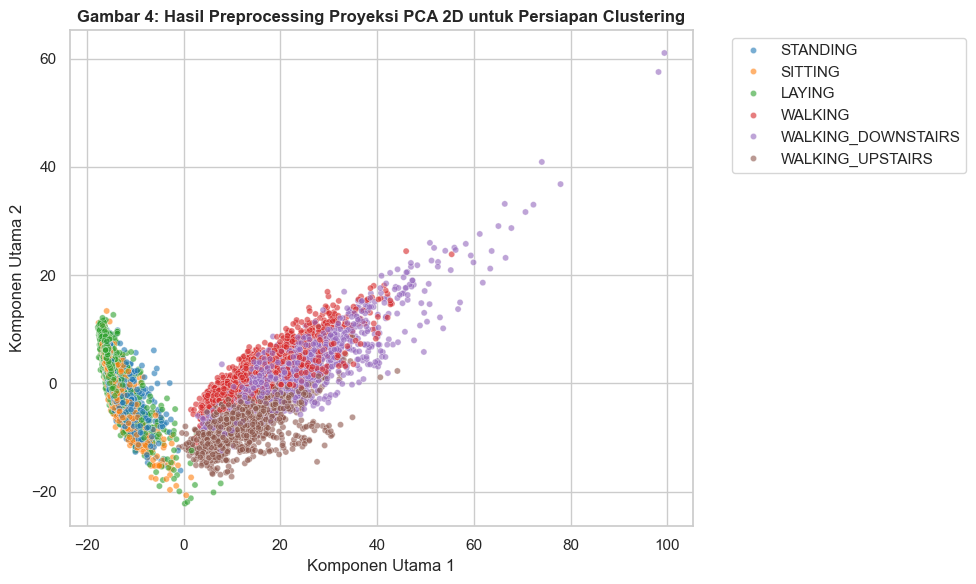

In [5]:
# 4. DATA PREPROCESSING (REDUKSI DIMENSI & SCALING)

print("\n=== 4. DATA PREPROCESSING ===")

# 2. FEATURE SELECTION (Memisahkan Matriks Input vs Metadata Ground Truth)
# Membuang metadata 'Subject', 'Activity', dan 'Activity_ID' dari matriks X
X = df_cleaned[column_names].values
y = df_cleaned['Activity'].values
subjects = df_cleaned['Subject'].values

print(f"\nUkuran Matriks Fitur (X) sebelum Scaling & PCA : {X.shape}")

# 3. STANDARDIZATION (Scaling)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. DIMENSIONALITY REDUCTION / FEATURE SELECTION VIA PCA
# Memilih komponen utama yang mempertahankan 90% varians data
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Ukuran Matriks Fitur (X) sesudah PCA (90% Varians) : {X_pca.shape}")
print(f"Jumlah Fitur Berhasil Direduksi : dari {X.shape[1]} menjadi {X_pca.shape[1]} komponen utama.")

# 5. VISUALISASI PROYEKSI PCA 2D HASIL PREPROCESSING
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_scaled)

df_pca_vis = pd.DataFrame(X_2d, columns=['PCA_Component_1', 'PCA_Component_2'])
df_pca_vis['Activity'] = y

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_pca_vis, 
    x='PCA_Component_1', 
    y='PCA_Component_2', 
    hue='Activity', 
    palette='tab10', 
    alpha=0.6,
    s=20
)
plt.title("Gambar 4: Hasil Preprocessing Proyeksi PCA 2D untuk Persiapan Clustering", fontsize=12, fontweight='bold')
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

#### Penjelasan Gambar 4 (Proyeksi Hasil Preprocessing):
Proyeksi 2D dari hasil StandardScaler dan PCA mengonfirmasi bahwa data siap klasterisasi. 
Terlihat dua klaster terpisah secara jelas pada Komponen Utama 1: kelompok aktivitas dinamis (WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS) di sebelah kiri dan kelompok aktivitas statis (LAYING, SITTING, STANDING) di sebelah kanan. Hasil transformasi ini akan menjadi input langsung pada pemodelan Agglomerative Hierarchical Clustering.

#### Penjelasan Feature Selection & Dimensionality Reduction
Alasan Membuang Fitur Metadata (`Subject`, `Activity`, `Activity_ID`): Fitur metadata ini dibuang dari input pemodelan karena Agglomerative Hierarchical Clustering merupakan algoritma unsupervised learning. Memasukkan ID subjek atau label aktivitas ke dalam input akan menyebabkan data leakage (kebocoran data). Activity hanya disimpan sebagai ground truth untuk validasi nilai ARI/NMI di tahap evaluasi.

Alasan Menggunakan Reduksi Dimensi PCA (Principal Component Analysis): Meskipun terdapat 561 fitur, banyak fitur sinyal yang memiliki korelasi tinggi (multikolinearitas) antara domain waktu dan frekuensi.   
- Mengatasi Curse of Dimensionality: Menghitung jarak Euclidean pada 561 dimensi membuat jarak antar-titik menjadi seragam dan menurunkan kualitas matrik jarak pada dendrogram.
- Feature Selection via Variance Threshold: Dengan menetapkan explained variance ratio sebesar 90%, kita dapat membuang noise dan mempertahankan informasi paling dominan. Dimensi berhasil direduksi dari 561 fitur menjadi ~64 komponen utama, menghemat memori komputasi secara drastis saat membangun matriks hierarki

|    Parameter    |             Kondisi Sebelum Diproses                | Kondisi Sesudah Diproses |	         Tindakan / Penanganan             |
|-----------------|-----------------------------------------------------|--------------------------|-----------------------------------------------|
|  Missing Values |                0 cells (0%)                         |        0 cells (0%)      |        Tidak memerlukan imputasi (fillna)     |
| Duplikasi Fitur |             0 baris duplikat                        |     0 baris duplikat     |            Dikonfirmasi data bersih           |
|    Nama Kolom   |	     42 nama terduplikasi di features.txt           |       561 nama unik      |    Diberi akhiran penanda unik (make_unique)  |
|   Skala Fitur   | Rentang $[-1, 1]$ (belum terstandarisasi $Z$-score) |      Mean = 0, Std = 1   |         Diaplikasikan StandardScaler          |
| Jumlah Dimensi  |                  561 Fitur                          | 64 Komponent Utama (PCA) | Dilakukan Feature Selection / Reduksi Dimensi |